<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta8g%C3%B6rev7ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

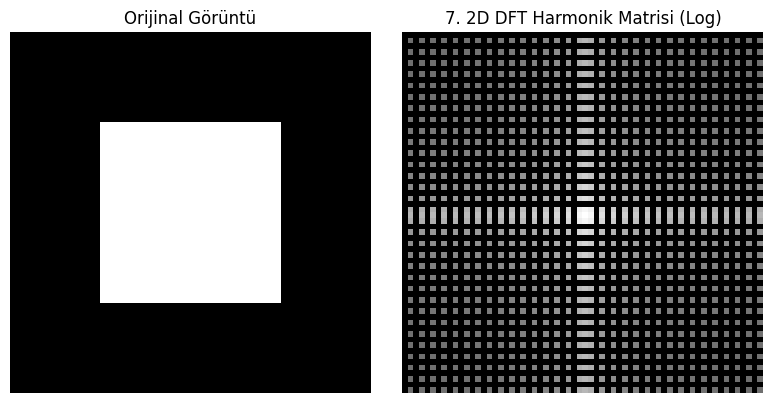

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def dft_2d(goruntu):
    f = np.asarray(goruntu, dtype=np.complex128)
    M, N = f.shape
    u = np.arange(M, dtype=np.float64).reshape((M, 1))
    x = np.arange(M, dtype=np.float64).reshape((1, M))
    v = np.arange(N, dtype=np.float64).reshape((N, 1))
    y = np.arange(N, dtype=np.float64).reshape((1, N))

    WU = np.exp(-2j * np.pi * (u @ x) / M)
    WV = np.exp(-2j * np.pi * (y.T @ v.T) / N)
    return WU @ f @ WV


# Örnek 64x64 gri görüntü
y_idx, x_idx = np.ogrid[:64, :64]
ornek_resim = np.zeros((64, 64), dtype=np.uint8)
ornek_resim[16:48, 16:48] = 200

harmonik_matris = dft_2d(ornek_resim)
spektrum = np.log1p(np.abs(np.fft.fftshift(harmonik_matris)))

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(ornek_resim, cmap="gray")
plt.title("Orijinal Görüntü")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(spektrum, cmap="gray")
plt.title("7. 2D DFT Harmonik Matrisi (Log)")
plt.axis("off")

plt.tight_layout()
plt.show()